# Обучение нейросетевых классификаторов

Исследуем применение небольшой полносвязной нейросети (MLP) к классификации записей КТГ. Для CLASS и NSP обучаем отдельные модели: первая определяет один из десяти паттернов, вторая — одно из трёх состояний. NSP не вычисляется автоматически из CLASS.

Используем подготовленные данные из 02_preparation.ipynb и то же разбиение, что в 03_classical_models.ipynb. Это позволяет сравнить классические и нейросетевые модели на одинаковых данных. В экспериментах проверим влияние архитектуры и настроек обучения на качество классификации.

## 1. Загрузка подготовленных данных

Загружаем train.csv, validation.csv и test.csv из runtime/data/prepared/. Эти файлы содержат 21 входной признак и две целевые колонки — CLASS и NSP. Идентификаторы и исключённые признаки удалены на этапе подготовки данных.

Сохраняем исходное групповое разбиение: все сегменты одного исследования находятся в одной части выборки. Train используем для обучения, validation — для выбора настроек, test — для итогового сравнения. Повторное разбиение не требуется.

Пути и общие настройки получаем из ExperimentSettings. Таблица после загрузки показывает размер каждой части выборки.

In [1]:
import pandas as pd

from experiments.settings import ExperimentSettings

experiment_settings = ExperimentSettings()

prepared_dir = experiment_settings.prepared_dir
splits = {name: pd.read_csv(prepared_dir / f"{name}.csv") for name in ["train", "validation", "test"]}

train_df = splits["train"]
validation_df = splits["validation"]
test_df = splits["test"]

pd.DataFrame({name: {"Строки": len(part), "Колонки": len(part.columns)} for name, part in splits.items()}).T

,Строки,Колонки
train,1266,23
validation,421,23
test,421,23


### Выделение входных признаков

Исключаем CLASS и NSP из списка входных колонок. Обе цели предсказываются по измерениям; значение одной цели не используется как признак для другой. Соответствия исходных кодов названиям категорий загружаем из src/classifier/constants.py для последующих отчётов.

In [2]:
from classifier.pipeline import dataset_schema

schema = dataset_schema.DatasetSchema()
from classifier.pipeline import dataset_schema

feature_cols = train_df.columns.drop(schema.target_columns).tolist()

## 2. Подготовка данных для PyTorch

### Настройки воспроизводимости

Фиксируем seed из ExperimentSettings для NumPy и PyTorch. Генераторы случайных чисел будут использоваться при инициализации весов сети и перемешивании обучающих записей. Фиксированный seed позволяет повторить эксперимент в том же окружении.

In [3]:
import numpy as np
import torch

np.random.seed(experiment_settings.random_state)
torch.manual_seed(experiment_settings.random_state);

### Масштабирование признаков

Признаки имеют разные единицы и диапазоны значений. Используем StandardScaler, чтобы привести их к сопоставимому масштабу перед обучением сети.

Средние и стандартные отклонения рассчитываем только по train. Для validation и test применяем те же значения, не обучая scaler повторно. Так информация из других частей выборки не влияет на подготовку обучающих данных.

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_features = {
    "train": scaler.fit_transform(train_df[feature_cols]),
    "validation": scaler.transform(validation_df[feature_cols]),
    "test": scaler.transform(test_df[feature_cols]),
}

### Тензоры и загрузчики данных

Преобразуем стандартизированные признаки в тензоры float32. Для CrossEntropyLoss метки должны быть одномерным массивом целых индексов классов. Вычитаем 1 из исходных кодов: CLASS получает индексы 0–9, NSP — 0–2. Метки сохраняем в torch.long. В отчётах индексы будут сопоставлены с исходными названиями категорий.

Для каждой цели и части выборки создаём TensorDataset, который хранит пары «признаки — метка». Входные признаки одинаковы для обеих целей, отличаются только метки.

DataLoader разбивает данные на небольшие группы — batch. Размер задаётся settings.batch_size, по умолчанию 32. Обучающие записи перемешиваем, чтобы сеть не проходила их в одном и том же порядке каждую эпоху. Validation и test оставляем в исходном порядке. Отдельные генераторы с фиксированным seed задают воспроизводимый порядок перемешивания. Последний неполный batch сохраняем, чтобы использовать все записи.

In [5]:
from torch.utils.data import DataLoader, TensorDataset

feature_tensors = {name: torch.tensor(values, dtype=torch.float32) for name, values in scaled_features.items()}
datasets = {}
loaders = {}
for target in dataset_schema.ClassificationTarget:
    datasets[target] = {}
    loaders[target] = {}
    for name, part in splits.items():
        labels = torch.tensor(part[target.value].to_numpy() - 1, dtype=torch.long)
        datasets[target][name] = TensorDataset(feature_tensors[name], labels)
        loaders[target][name] = DataLoader(
            datasets[target][name],
            batch_size=experiment_settings.neural_batch_size,
            shuffle=name == "train",
            generator=torch.Generator().manual_seed(experiment_settings.random_state),
        )

### Подготовленные тензоры

Выводим размеры тензоров, их типы и индексы классов для train. Входной тензор содержит по 21 признаку на запись, а целевой — по одной метке. CLASS содержит 10 категорий, NSP — 3.

In [6]:
for target in dataset_schema.ClassificationTarget:
    features, labels = datasets[target]["train"].tensors
    mapping = target.mappings
    print(
        f"{target.value}: признаки {tuple(features.shape)}, {features.dtype}; метки {tuple(labels.shape)}, {labels.dtype}",
    )
    print(f"Индексы классов: {labels.unique().tolist()}; категорий: {len(mapping)}")

print(f"Batch size: {experiment_settings.neural_batch_size}")

CLASS: признаки (1266, 21), torch.float32; метки (1266,), torch.int64
Индексы классов: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]; категорий: 10
NSP: признаки (1266, 21), torch.float32; метки (1266,), torch.int64
Индексы классов: [0, 1, 2]; категорий: 3
Batch size: 32


**Вывод.** Подготовлены три части выборки: train — 1266 записей, validation и test — по 421. Для каждой цели созданы тензоры и загрузчики данных. Признаки стандартизированы по train; метки приведены к целым индексам классов. Следующий этап — создание MLP и обучение на подготовленных batch.

## 3. Устройство небольшой MLP

Начинаем с одного скрытого слоя: 21 входной признак → 32 нейрона → выход. Небольшая сеть даёт понятный исходный вариант, с которым будем сравнивать дальнейшие изменения.

Первый Linear вычисляет взвешенные комбинации признаков. ReLU добавляет нелинейность: без неё несколько линейных слоёв свелись бы к одному линейному преобразованию. Последний Linear выдаёт по одной оценке для каждой категории: 10 для CLASS и 3 для NSP.

Эти оценки называются logits. Softmax в сеть не добавляем: CrossEntropyLoss сама выполняет необходимое преобразование при расчёте ошибки. Для выбора категории достаточно argmax — индекса наибольшей оценки. Вероятности для интерфейса понадобятся позже.

Размер скрытого слоя берём из ExperimentSettings. Пока не используем Dropout и веса классов, чтобы сначала оценить простую архитектуру.

In [6]:
from torch import nn


class MulticlassMLP(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, output_size: int):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, output_size),
        )

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        return self.network(features)


target_mappings = {
    dataset_schema.ClassificationTarget.CLASS: dataset_schema.ClassificationTarget.CLASS.mappings,
    dataset_schema.ClassificationTarget.NSP: dataset_schema.ClassificationTarget.NSP.mappings,
}
for target, mapping in target_mappings.items():
    example_model = MulticlassMLP(len(feature_cols), experiment_settings.neural_hidden_size, len(mapping))
    print(f"{target.value}: {example_model}")
    print(f"Обучаемых параметров: {sum(parameter.numel() for parameter in example_model.parameters())}")

CLASS: MulticlassMLP(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=10, bias=True)
  )
)
Обучаемых параметров: 1034
NSP: MulticlassMLP(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=3, bias=True)
  )
)
Обучаемых параметров: 803


**Вывод.** Сеть для CLASS содержит 1034 обучаемых параметра, для NSP — 803. Различается только выходной слой. Эта архитектура достаточно мала для обучения на CPU Mac; более сложную сеть проверим отдельным экспериментом.

## 4. Цикл обучения и исходная MLP

### Настройки эксперимента и MLflow

Для обеих целей используем одинаковые исходные настройки: Adam, learning rate 0,001, batch size 32 и не более 50 эпох. Эпоха — один проход по всем обучающим записям. Значения берём из ExperimentSettings и сохраняем в MLflow.

Каждая цель получает отдельный запуск в эксперименте neural_classifiers. Записываем архитектуру, настройки, историю обучения и модель лучшей эпохи. Это исходные нейросетевые варианты; согласованным baseline всего проекта остаётся RandomForest из предыдущего блокнота.

In [7]:
import logging
import os
import subprocess

from classifier.pipeline import dataset_schema

os.environ["MLFLOW_LOGGING_LEVEL"] = "WARNING"
os.environ["MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT"] = "true"
os.environ["MLFLOW_PRINT_MODEL_URLS_ON_CREATION"] = "false"

for variable in ["NO_PROXY", "no_proxy"]:
    os.environ[variable] = ",".join(filter(None, [os.environ.get(variable, ""), "localhost", "127.0.0.1"]))

logging.getLogger("mlflow").setLevel(logging.WARNING)
logging.getLogger("mlflow.utils.environment").addFilter(
    lambda record: not record.getMessage().startswith("Failed to resolve installed pip version."),
)

In [8]:
import mlflow
import mlflow.pytorch

subprocess.run(["just", "mlflow-start"], cwd=dataset_schema.PROJECT_ROOT, check=True)
mlflow.set_tracking_uri(experiment_settings.mlflow_tracking_uri)
mlflow.set_experiment(experiment_settings.neural_mlflow_experiment_name)

model_requirements = (dataset_schema.PROJECT_ROOT / "runtime/models/neural/requirements.txt").read_text().splitlines()
print(
    f"MLflow: {experiment_settings.mlflow_tracking_uri}; эксперимент: {experiment_settings.neural_mlflow_experiment_name}",
)

Порт 5001 уже занят — повторный запуск пропущен
MLflow: http://127.0.0.1:5001; эксперимент: neural_classifiers


### Как обновляются веса и выбирается эпоха

На каждом обучающем batch выполняем пять действий:

1. optimizer.zero_grad() — обнуляем градиенты предыдущего batch.
2. model(batch_features) — получаем logits текущей сети.
3. CrossEntropyLoss — рассчитываем ошибку относительно правильных меток.
4. loss.backward() — вычисляем, как изменение каждого веса влияет на ошибку.
5. optimizer.step() — Adam обновляет веса с использованием градиентов.

После каждой эпохи переводим сеть в model.eval() и оцениваем train и validation без градиентов. Эти небольшие выборки помещаются в память, поэтому для оценки подаём каждую целиком. Обе оценки относятся к одному состоянию весов после завершения эпохи; loss усредняется по всем записям выборки.

Loss используется для обучения; macro-F1 — для выбора лучшей эпохи. Сохраняем копию весов при улучшении validation macro-F1. Если улучшения нет 10 эпох подряд, останавливаем обучение. В конце восстанавливаем лучшие веса, даже если последняя эпоха оказалась хуже.

Перед обучением каждой цели заново создаём сеть и сбрасываем seed и генератор перемешивания. Повторное выполнение ячейки начинает новый эксперимент с исходных весов. Test здесь не оценивается.

Функция train_mlp содержит только обучение, оценку по эпохам и восстановление лучших весов. Она изменяет переданную модель и возвращает историю обучения и номер лучшей эпохи. Сохранение в MLflow выполняется отдельно.

In [9]:
from copy import deepcopy

from pydantic import BaseModel, Field
from sklearn.metrics import accuracy_score, f1_score


class MLPParameters(BaseModel):
    hidden_layers: list[int] = Field(min_length=1)
    dropout: float = Field(ge=0, lt=1)
    learning_rate: float = Field(gt=0)
    max_epochs: int = Field(gt=0)
    patience: int = Field(gt=0)
    weight_decay: float = Field(ge=0)
    use_class_weights: bool


def train_mlp(
    model: nn.Module,
    target: dataset_schema.ClassificationTarget,
    parameters: MLPParameters | None = None,
) -> tuple[pd.DataFrame, int]:
    parameters = parameters or MLPParameters(
        hidden_layers=[experiment_settings.neural_hidden_size],
        learning_rate=experiment_settings.neural_learning_rate,
        max_epochs=experiment_settings.neural_max_epochs,
        patience=experiment_settings.neural_patience,
        dropout=experiment_settings.neural_dropout,
        weight_decay=experiment_settings.neural_weight_decay,
        use_class_weights=experiment_settings.neural_use_class_weights,
    )
    mapping = target_mappings[target]
    class_weights = None
    if parameters.use_class_weights:
        labels = datasets[target]["train"].tensors[1]
        counts = torch.bincount(labels, minlength=len(mapping))
        class_weights = len(labels) / (len(mapping) * counts.float())
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=parameters.learning_rate,
        weight_decay=parameters.weight_decay,
    )
    history = []
    best_score = -1.0
    epochs_without_improvement = 0

    for epoch in range(1, parameters.max_epochs + 1):
        model.train()
        for batch_features, batch_labels in loaders[target]["train"]:
            optimizer.zero_grad()
            logits = model(batch_features)
            loss = criterion(logits, batch_labels)
            loss.backward()
            optimizer.step()

        model.eval()
        epoch_metrics = {}
        with torch.no_grad():
            for name in ["train", "validation"]:
                features, labels = datasets[target][name].tensors
                logits = model(features)
                predictions = logits.argmax(dim=1).numpy()
                epoch_metrics[f"{name}_loss"] = criterion(logits, labels).item()
                epoch_metrics[f"{name}_macro_f1"] = f1_score(
                    labels.numpy(),
                    predictions,
                    labels=list(range(len(mapping))),
                    average="macro",
                    zero_division=0,
                )
                epoch_metrics[f"{name}_weighted_f1"] = f1_score(
                    labels.numpy(),
                    predictions,
                    average="weighted",
                    zero_division=0,
                )
                epoch_metrics[f"{name}_accuracy"] = accuracy_score(labels.numpy(), predictions)
        history.append({"epoch": epoch, **epoch_metrics})

        if epoch_metrics["validation_macro_f1"] > best_score:
            best_score = epoch_metrics["validation_macro_f1"]
            best_epoch = epoch
            best_weights = deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if epochs_without_improvement >= parameters.patience:
            break

    model.load_state_dict(best_weights)
    model.eval()
    return pd.DataFrame(history), best_epoch

### Запуск обучения для двух целей

Для CLASS и NSP создаём отдельные сети и вызываем одну и ту же функцию train_mlp. Перед каждым запуском фиксируем seed и порядок перемешивания. Сохраняем обученные модели, историю и номер лучшей эпохи для последующего анализа.

In [11]:
neural_models = {}
training_histories = {}
training_summaries = {}

for target, mapping in target_mappings.items():
    torch.manual_seed(experiment_settings.random_state)
    loaders[target]["train"].generator.manual_seed(experiment_settings.random_state)
    model = MulticlassMLP(len(feature_cols), experiment_settings.neural_hidden_size, len(mapping))
    history, best_epoch = train_mlp(model, target)
    neural_models[target] = model
    training_histories[target] = history
    training_summaries[target] = {"best_epoch": best_epoch, "epochs_completed": len(history)}
    best_score = history.iloc[best_epoch - 1]["validation_macro_f1"]
    print(
        f"{target.value}: выполнено {len(history)} эпох; лучшая эпоха {best_epoch}; "
        f"validation macro-F1 = {best_score:.4f}",
    )

CLASS: выполнено 50 эпох; лучшая эпоха 50; validation macro-F1 = 0.7431


NSP: выполнено 50 эпох; лучшая эпоха 49; validation macro-F1 = 0.7934


### Сохранение результатов в MLflow

После обучения записываем параметры, метрики каждой эпохи и модель с восстановленными лучшими весами. Эта ячейка использует уже полученные результаты и не выполняет обучение повторно. Идентификаторы запусков сохраняем для добавления отчётов в пункте 5.

In [12]:
neural_run_ids = {}
for target, model in neural_models.items():
    history = training_histories[target].to_dict("records")
    with mlflow.start_run(run_name=f"{target.value}_MLP_initial") as run:
        mlflow.set_tags({"target": target.value, "model_type": "MLP", "role": "initial_neural"})
        mlflow.log_params(
            {
                "random_state": experiment_settings.random_state,
                "hidden_size": experiment_settings.neural_hidden_size,
                "batch_size": experiment_settings.neural_batch_size,
                "learning_rate": experiment_settings.neural_learning_rate,
                "max_epochs": experiment_settings.neural_max_epochs,
                "patience": experiment_settings.neural_patience,
                "optimizer": "Adam",
                "loss": "CrossEntropyLoss",
                "input_size": len(feature_cols),
                "output_size": len(target_mappings[target]),
                "device": "cpu",
                **training_summaries[target],
            },
        )
        for record in history:
            mlflow.log_metrics(
                {f"epoch_{name}": value for name, value in record.items() if name != "epoch"},
                step=int(record["epoch"]),
            )
        mlflow.log_dict({"epochs": history}, "training_history.json")
        mlflow.log_dict(
            {
                "features": feature_cols,
                "target_mapping": target_mappings[target],
                "scaler_mean": scaler.mean_.tolist(),
                "scaler_scale": scaler.scale_.tolist(),
            },
            "input_schema.json",
        )
        mlflow.pytorch.log_model(
            model,
            name="model",
            input_example=feature_tensors["train"][:5].numpy(),
            pip_requirements=model_requirements,
        )
        neural_run_ids[target] = run.info.run_id

### Вывод по обучению

- Для обеих целей выполнено 50 эпох: ранняя остановка не сработала, поскольку улучшения validation продолжались в пределах заданного ожидания.
- Для CLASS выбрана эпоха 50: validation macro-F1 = 0,743. Лучший результат получен на границе бюджета, поэтому 50 эпох не считаем доказанно оптимальным числом.
- Для NSP выбрана эпоха 49: validation macro-F1 = 0,793. На эпохе 50 он снизился до 0,784, поэтому восстановлены веса эпохи 49.

Обновление весов уменьшило ошибку и улучшило классификацию относительно первой эпохи. Далее проверяем не только общий результат, но и разрыв train/validation и ошибки отдельных категорий.

## 5. Разбор обучения и ошибок

### Кривые обучения

Для каждой цели показываем train и validation на двух графиках: loss и macro-F1. Уменьшение train loss означает, что обновление весов снижает ошибку на обучающих данных. Validation показывает, переносится ли это улучшение на другие исследования.

Если train продолжает улучшаться, а validation перестаёт улучшаться или ухудшается, это признак переобучения. Вертикальной линией отмечаем выбранную эпоху. Все последующие отчёты относятся к восстановленным весам этой эпохи.

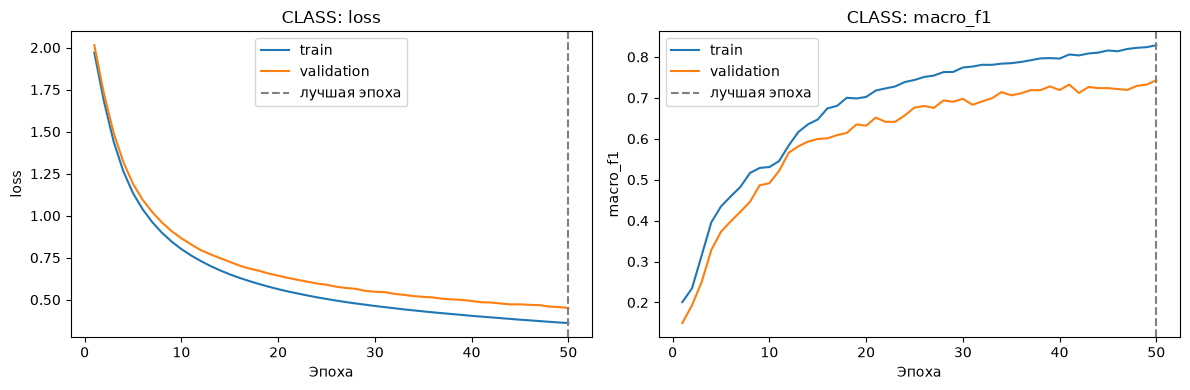

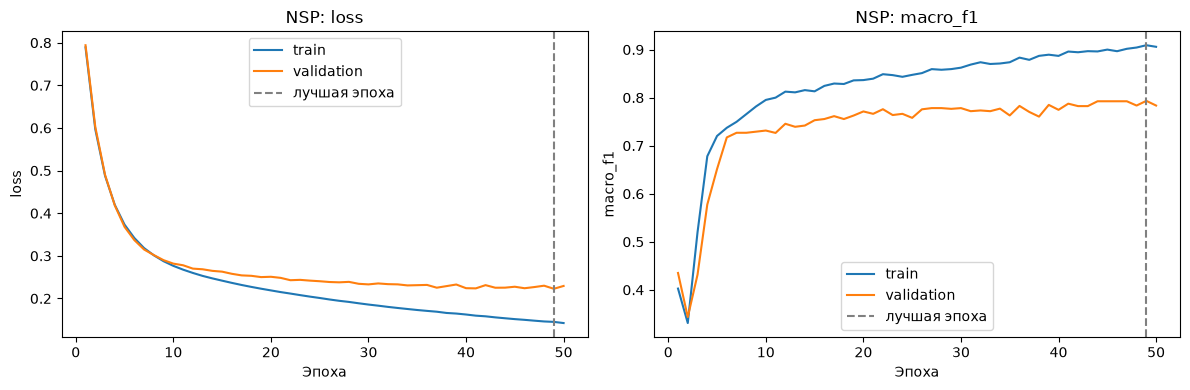

In [13]:
import matplotlib.pyplot as plt

for target, history in training_histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["loss", "macro_f1"]):
        ax.plot(history["epoch"], history[f"train_{metric}"], label="train")
        ax.plot(history["epoch"], history[f"validation_{metric}"], label="validation")
        ax.axvline(training_summaries[target]["best_epoch"], color="grey", linestyle="--", label="лучшая эпоха")
        ax.set_title(f"{target.value}: {metric}")
        ax.set_xlabel("Эпоха")
        ax.set_ylabel(metric)
        ax.legend()
    fig.tight_layout()
    plt.show()

### Качество выбранной эпохи

Рассчитываем метрики заново после восстановления лучших весов. Индексы предсказаний возвращаем к исходным кодам, прибавляя 1. При расчёте отчёта явно задаём все категории, включая те, которые сеть не предсказала.

Основная метрика — macro-F1: классы имеют одинаковый вес. Weighted-F1 и accuracy дополняют оценку, но сильнее зависят от частых категорий. Для NSP высокие значения этих метрик могут скрывать пропуски Suspect и Pathologic. Если macro-F1 растёт, а weighted-F1 падает, проверяем, не улучшились ли редкие категории за счёт частых.

In [14]:
from sklearn.metrics import classification_report, confusion_matrix

neural_evaluations = {}
quality_rows = []
for target, model in neural_models.items():
    neural_evaluations[target] = {}
    model.eval()
    with mlflow.start_run(run_id=neural_run_ids[target]):
        for name in ["train", "validation"]:
            features, labels = datasets[target][name].tensors
            with torch.no_grad():
                predictions = model(features).argmax(dim=1).numpy() + 1
            true_labels = labels.numpy() + 1
            mapping = target_mappings[target]
            report = classification_report(
                true_labels,
                predictions,
                labels=list(mapping),
                target_names=list(mapping.values()),
                output_dict=True,
                zero_division=0,
            )
            metrics = {
                "macro_f1": report["macro avg"]["f1-score"],
                "weighted_f1": report["weighted avg"]["f1-score"],
                "accuracy": accuracy_score(true_labels, predictions),
            }
            matrix = confusion_matrix(true_labels, predictions, labels=list(mapping))
            neural_evaluations[target][name] = {"metrics": metrics, "report": report, "confusion": matrix}
            mlflow.log_metrics({f"{name}_{key}": value for key, value in metrics.items()})
            for label in mapping.values():
                mlflow.log_metrics(
                    {
                        f"{name}_{label}_{metric.replace('f1-score', 'f1')}": report[label][metric]
                        for metric in ["precision", "recall", "f1-score"]
                    },
                )
            mlflow.log_dict(report, f"{name}/classification_report.json")
            mlflow.log_dict(
                {"labels": list(mapping.values()), "matrix": matrix.tolist()},
                f"{name}/confusion_matrix.json",
            )
            quality_rows.append({"Цель": target.value, "Выборка": name, **metrics})

display(pd.DataFrame(quality_rows).round(4))

,Цель,Выборка,macro_f1,weighted_f1,accuracy
0,CLASS,train,0.8286,0.8771,0.8784
1,CLASS,validation,0.7431,0.8267,0.8337
2,NSP,train,0.9091,0.9467,0.9463
3,NSP,validation,0.7934,0.8961,0.9026


### Качество отдельных категорий

Показываем precision, recall и F1 на validation. Recall отвечает на вопрос, сколько записей категории обнаружено; precision — сколько предсказаний этой категории оказались верными. F1 объединяет эти две оценки.

Под названием категории указываем n — число её записей в validation. Для редких категорий одна дополнительная ошибка заметно изменяет оценку. Таблицу полного classification_report не выводим: нужные показатели видны на графиках.

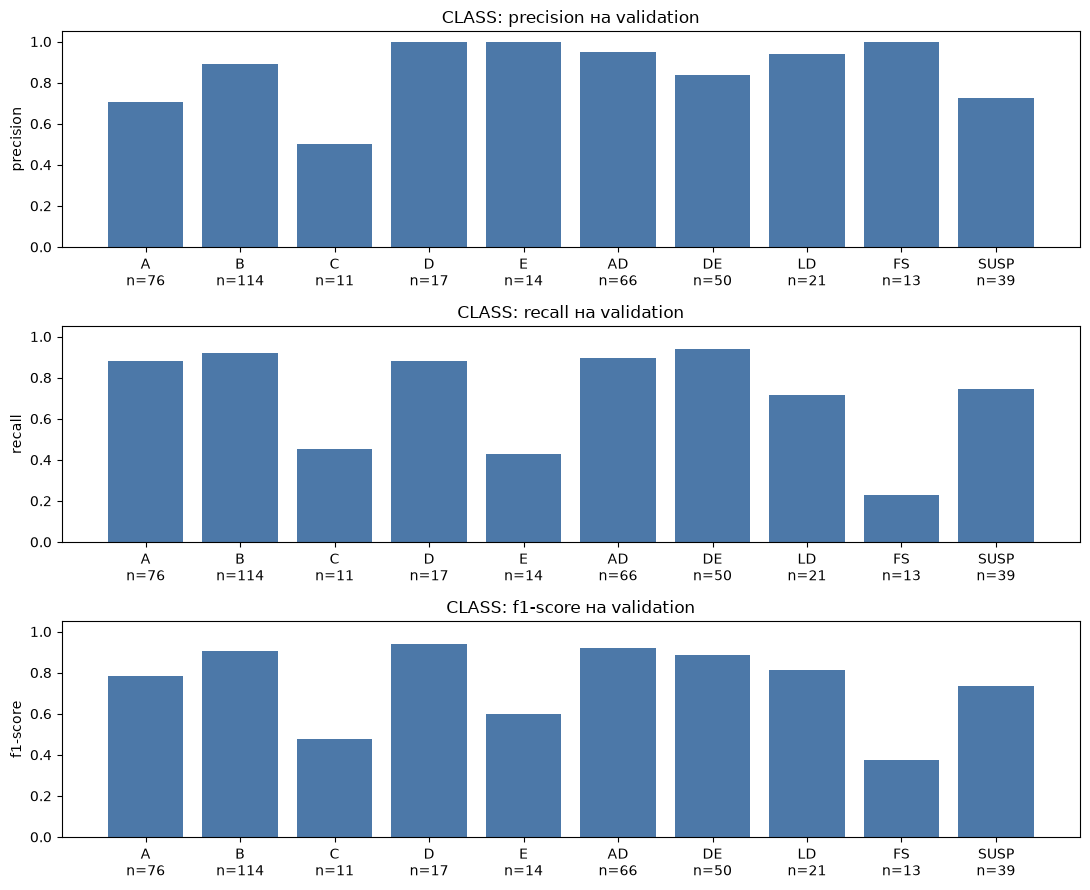

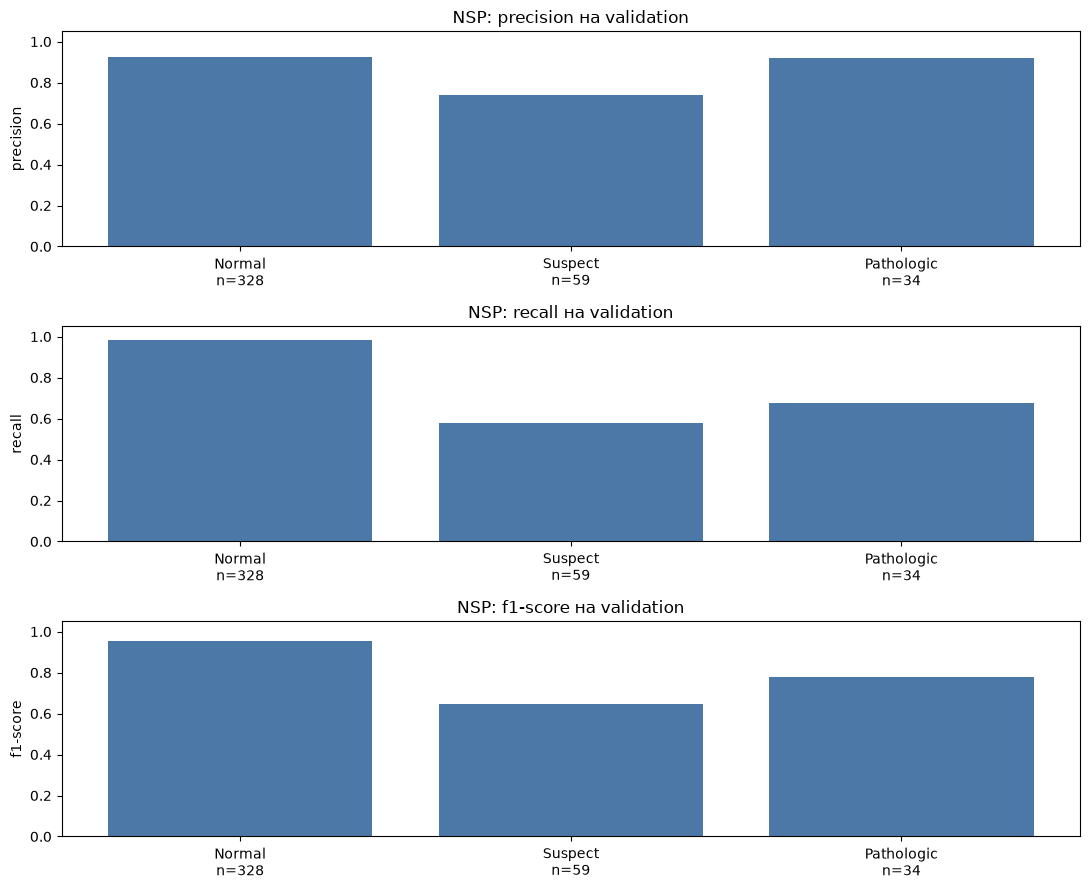

In [15]:
for target, mapping in target_mappings.items():
    report = neural_evaluations[target]["validation"]["report"]
    fig, axes = plt.subplots(3, 1, figsize=(11, 9))
    for ax, metric in zip(axes, ["precision", "recall", "f1-score"]):
        ax.bar(list(mapping.values()), [report[label][metric] for label in mapping.values()], color="#4c78a8")
        ax.set_ylim(0, 1.05)
        ax.set_title(f"{target.value}: {metric} на validation")
        ax.set_xticks(
            range(len(mapping)),
            [f"{label}\nn={int(report[label]['support'])}" for label in mapping.values()],
        )
        ax.set_ylabel(metric)
    fig.tight_layout()
    plt.show()

### Матрицы ошибок и приоритизация NSP

Строки матрицы — истинные категории, столбцы — предсказанные. Диагональ содержит правильные ответы; остальные ячейки показывают, какие категории перепутаны.

Для сценария приоритизации отдельно считаем записи, которые сеть оставила без предупреждения: Pathologic → Normal и Suspect → Normal. Ложное предупреждение для Normal менее вредно, но увеличивает объём проверки. Pathologic → Suspect сохраняет предупреждение, хотя категория состояния занижена.

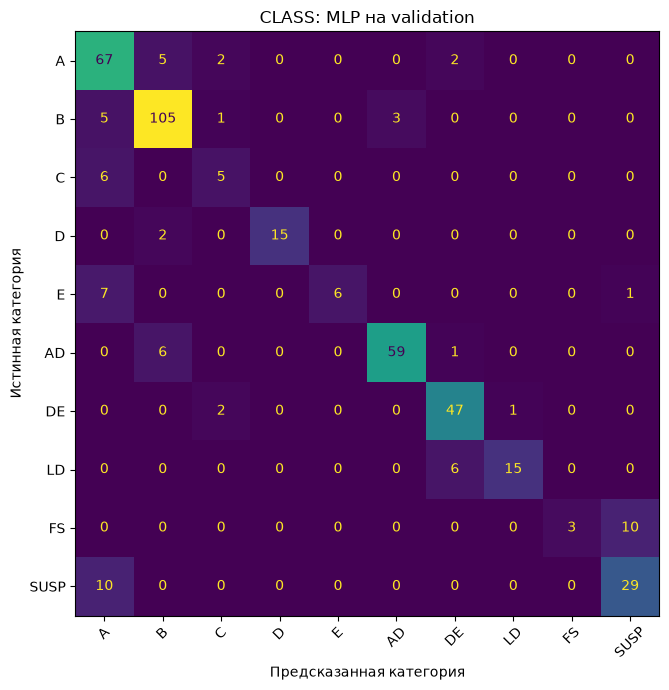

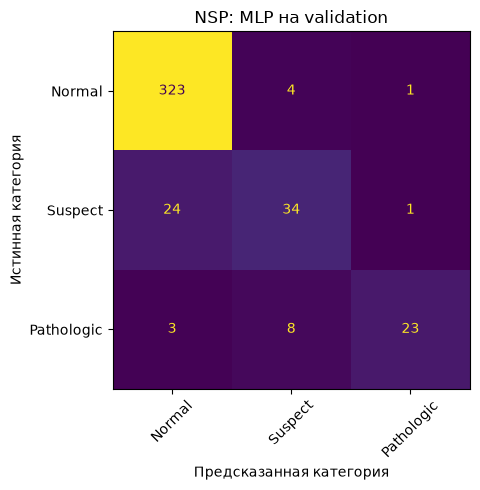

,Pathologic → Normal,Suspect → Normal,Pathologic → Suspect,Normal → Suspect/Pathologic
Исходная MLP,3,24,8,5


In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

for target, mapping in target_mappings.items():
    fig, ax = plt.subplots(figsize=(8, 7) if target == dataset_schema.ClassificationTarget.CLASS else (6, 5))
    ConfusionMatrixDisplay(
        confusion_matrix=neural_evaluations[target]["validation"]["confusion"],
        display_labels=list(mapping.values()),
    ).plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(f"{target.value}: MLP на validation")
    ax.set_xlabel("Предсказанная категория")
    ax.set_ylabel("Истинная категория")
    fig.tight_layout()
    plt.show()

matrix = neural_evaluations[dataset_schema.ClassificationTarget.NSP]["validation"]["confusion"]
display(
    pd.DataFrame(
        [
            {
                "Pathologic → Normal": int(matrix[2, 0]),
                "Suspect → Normal": int(matrix[1, 0]),
                "Pathologic → Suspect": int(matrix[2, 1]),
                "Normal → Suspect/Pathologic": int(matrix[0, 1] + matrix[0, 2]),
            },
        ],
        index=["Исходная MLP"],
    ),
)

### Выводы по исходной MLP

**1. Обучение и перенос на другие исследования.**

- **CLASS:** loss уменьшается на обеих выборках. Macro-F1 выбранной эпохи составляет 0,829 на train и 0,743 на validation; разрыв — 0,086. Сеть обучается и улучшает validation, но часть ошибок остаётся. По этим кривым преждевременно объяснять все ошибки переобучением: validation loss продолжает снижаться.
- **NSP:** на поздних эпохах train продолжает улучшаться, а validation меняется заметно слабее. Macro-F1 составляет 0,909 на train и 0,793 на validation; разрыв — 0,116. Есть признаки переобучения; ограничение числа эпох и восстановление лучших весов не устраняют этот разрыв.

**2. Паттерны CLASS, требующие внимания.**

- **FS:** найдены 3 из 13 записей (recall 0,231); остальные 10 отнесены к SUSP. Это самая слабая категория по F1 — 0,375.
- **E:** найдены 6 из 14 записей (recall 0,429); 7 записей отнесены к A, ещё одна — к SUSP.
- **C:** найдены 5 из 11 записей (recall 0,455); оставшиеся 6 отнесены к A.
- **D:** найдены 15 из 17 записей (recall 0,882), все 15 предсказаний D верны (precision 1). Редкие категории распознаются неодинаково: небольшой объём данных сам по себе не объясняет все различия.

Для E и FS precision также равен 1, но recall низкий: сеть редко выбирает эти категории и пропускает значительную часть их записей. Поэтому при улучшении модели учитываем обе метрики.

**3. NSP и приоритизация записей.**

- Из 34 Pathologic правильно определены 23 (recall 0,676). Три записи отнесены к Normal и остались без предупреждения; восемь — к Suspect, с сохранением предупреждения и заниженной категорией.
- Из 59 Suspect правильно определены 34 (recall 0,576). Ещё 24 записи отнесены к Normal, одна — к Pathologic. Таким образом, повышенный приоритет получили 35 из 59 подозрительных записей.
- Из 328 Normal пять получили ложное предупреждение. По приоритетам сервиса такие ошибки менее вредны, чем пропуски Suspect и Pathologic.
- Accuracy 0,903 и weighted-F1 0,896 отражают в том числе хорошее распознавание частого Normal. Они не отменяют 27 записей Suspect/Pathologic, оставшихся без предупреждения.

**4. Результат исходного варианта и следующий шаг.**

Исходная MLP уступает baseline RandomForest по validation macro-F1: CLASS — 0,743 против 0,780; NSP — 0,793 против 0,865. Для NSP у baseline меньше пропусков без предупреждения: Pathologic → Normal — 2 против 3, Suspect → Normal — 14 против 24.

Следующим шагом запустим подбор архитектуры, learning rate, регуляризации и весов классов. Увеличим предел эпох для CLASS, поскольку исходная сеть достигла лучшего результата на последней из 50. Результаты рассмотрим в таблицах и вручную выберем нейросетевые кандидаты. Test остаётся для итоговой проверки.

## 6. Подбор параметров MLP

В пунктах 4–5 обучены **две исходные сети**: одна для CLASS, другая для NSP. Теперь отдельно запускаем по **25 попыток Optuna** для каждой цели. Каждая попытка обучает новую сеть с другими параметрами.

Всего при одном полном выполнении этого блокнота обучаются **52 сети: 2 исходные + 25 для CLASS + 25 для NSP**. Сохранение выбранных моделей не добавляет новых обучений. Ранее выполненные пробные эксперименты остались в истории MLflow, но из текущего порядка работы исключены.

Порядок действий: запускаем подбор → рассматриваем таблицу → вручную указываем выбранную попытку. Test не используем.

### 6.1. Что подбираем

Проверяем размер и количество скрытых слоёв, Dropout, learning rate, weight decay и использование весов классов. Архитектуры заданы небольшим списком. Для каждого скрытого слоя используется Linear → ReLU; последний слой выдаёт оценки категорий.

Dropout обнуляет часть выходов скрытого слоя при обучении и отключается при оценке. Weight decay ограничивает рост весов. При включении весов классов ошибки редких категорий получают больший вес; частоты рассчитываются только по train.

Одна попытка допускает **до 150 эпох**. Если validation macro-F1 не улучшается **20 эпох подряд**, обучение завершается раньше. Сохраняем веса эпохи с наибольшим validation macro-F1. Бюджет и ограничения берём из ExperimentSettings; batch size остаётся 32.

In [10]:
class ConfigurableMLP(nn.Module):
    def __init__(self, input_size: int, output_size: int, parameters: MLPParameters):
        super().__init__()
        layers = []
        previous_size = input_size
        for hidden_size in parameters.hidden_layers:
            layers.extend([nn.Linear(previous_size, hidden_size), nn.ReLU()])
            if parameters.dropout > 0:
                layers.append(nn.Dropout(parameters.dropout))
            previous_size = hidden_size
        layers.append(nn.Linear(previous_size, output_size))
        self.network = nn.Sequential(*layers)

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        return self.network(features)

In [18]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
architectures = experiment_settings.neural_architectures

### 6.2. Подбор для CLASS

Objective получает параметры от Optuna, создаёт сеть и вызывает уже разобранную train_mlp. Перед каждой попыткой фиксируем seed и порядок batch. Функция возвращает лучший validation macro-F1; history содержит результаты всех выполненных эпох.

Модель, параметры и история каждой попытки остаются в class_results. В MLflow записываем настройки, метрики лучшей эпохи и историю. Первая попытка проверяет один слой из 32 нейронов и learning rate 0,003 — уже найденный удачный вариант. Остальные параметры выбирает TPE.

In [19]:
class_results = {}


def class_objective(trial):
    parameters = MLPParameters(
        hidden_layers=architectures[trial.suggest_categorical("architecture", list(architectures))],
        dropout=trial.suggest_categorical("dropout", experiment_settings.neural_dropout_choices),
        learning_rate=trial.suggest_float("learning_rate", *experiment_settings.neural_learning_rate_range, log=True),
        weight_decay=trial.suggest_categorical("weight_decay", experiment_settings.neural_weight_decay_choices),
        use_class_weights=trial.suggest_categorical(
            "use_class_weights",
            experiment_settings.neural_class_weight_choices,
        ),
        max_epochs=experiment_settings.neural_search_max_epochs,
        patience=experiment_settings.neural_search_patience,
    )
    torch.manual_seed(experiment_settings.random_state)
    loaders[dataset_schema.ClassificationTarget.CLASS]["train"].generator.manual_seed(experiment_settings.random_state)
    model = ConfigurableMLP(len(feature_cols), len(dataset_schema.ClassificationTarget.CLASS.mappings), parameters)
    history, best_epoch = train_mlp(model, dataset_schema.ClassificationTarget.CLASS, parameters)
    metrics = history.iloc[best_epoch - 1].drop("epoch").to_dict()
    with mlflow.start_run(run_name=f"CLASS_optuna_{trial.number}") as run:
        mlflow.log_params(
            {
                **parameters.model_dump(),
                "target": "CLASS",
                "random_state": experiment_settings.random_state,
                "batch_size": experiment_settings.neural_batch_size,
                "best_epoch": best_epoch,
                "epochs_completed": len(history),
            },
        )
        mlflow.log_metrics(metrics)
        mlflow.log_dict({"epochs": history.to_dict("records")}, "training_history.json")
        class_results[trial.number] = {
            "model": model,
            "parameters": parameters,
            "history": history,
            "best_epoch": best_epoch,
            "metrics": metrics,
            "run_id": run.info.run_id,
        }
    return metrics["validation_macro_f1"]

**Запуск подбора CLASS.** Выполняем 25 попыток. Seed TPE зафиксирован; поиск использует только validation. После завершения этой ячейки рассматриваем результаты.

In [20]:
class_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=experiment_settings.random_state),
)
class_study.enqueue_trial(
    {
        "architecture": "32",
        "dropout": 0.0,
        "learning_rate": 0.003,
        "weight_decay": 0.0,
        "use_class_weights": False,
    },
)
class_study.optimize(class_objective, n_trials=experiment_settings.neural_optuna_budget)

**Результаты CLASS.** Показываем пять попыток с наибольшим macro-F1. «Лучшая эпоха» — веса, которые сохраняем; «Выполнено эпох» — сколько эпох сеть обучалась до остановки. Таблица только показывает результаты и не выбирает модель.

In [21]:
class_table = pd.DataFrame(
    {
        number: {
            "Лучшая эпоха": result["best_epoch"],
            "Выполнено эпох": len(result["history"]),
            "macro_f1": result["metrics"]["validation_macro_f1"],
            "weighted_f1": result["metrics"]["validation_weighted_f1"],
            "accuracy": result["metrics"]["validation_accuracy"],
        }
        for number, result in class_results.items()
    },
).T
class_table.index.name = "Попытка"
class_table.sort_values("macro_f1", ascending=False).head(5).round(4)

,Лучшая эпоха,Выполнено эпох,macro_f1,weighted_f1,accuracy
Попытка,,,,,
0,33.0,53.0,0.8429,0.8754,0.8765
11,102.0,122.0,0.8408,0.8837,0.8860
13,76.0,96.0,0.8384,0.8842,0.8860
18,83.0,103.0,0.8345,0.8753,0.8765
23,60.0,80.0,0.8342,0.8780,0.8789


**Ручной выбор CLASS: попытка №0.** Macro-F1 — 0,843, weighted-F1 — 0,875, accuracy — 0,876. Слой из 32 нейронов, learning rate 0,003; без Dropout, weight decay и весов классов. Лучшие веса — эпоха 33; обучение завершилось на эпохе 53.

Попытка №11 дала weighted-F1 0,884 и accuracy 0,886, но меньший macro-F1 — 0,841. По основной метрике выбираем №0. Более глубокие сети в этом поиске его не превзошли.

In [22]:
class_selected_trial = 0
class_selected = class_results[class_selected_trial]

### 6.3. Подбор для NSP

Отдельно запускаем тот же поиск для трёх состояний NSP. Первая попытка использует веса классов: ранее это улучшило обнаружение Suspect и Pathologic.

Дополнительно считаем Pathologic → Normal, Suspect → Normal и ложные предупреждения для Normal. Они нужны для ручного разбора результатов, но не добавляются в скрытый алгоритм выбора.

In [23]:
nsp_results = {}


def nsp_objective(trial):
    parameters = MLPParameters(
        hidden_layers=architectures[trial.suggest_categorical("architecture", list(architectures))],
        dropout=trial.suggest_categorical("dropout", experiment_settings.neural_dropout_choices),
        learning_rate=trial.suggest_float("learning_rate", *experiment_settings.neural_learning_rate_range, log=True),
        weight_decay=trial.suggest_categorical("weight_decay", experiment_settings.neural_weight_decay_choices),
        use_class_weights=trial.suggest_categorical(
            "use_class_weights",
            experiment_settings.neural_class_weight_choices,
        ),
        max_epochs=experiment_settings.neural_search_max_epochs,
        patience=experiment_settings.neural_search_patience,
    )
    torch.manual_seed(experiment_settings.random_state)
    loaders[dataset_schema.ClassificationTarget.NSP]["train"].generator.manual_seed(experiment_settings.random_state)
    model = ConfigurableMLP(len(feature_cols), len(dataset_schema.ClassificationTarget.NSP.mappings), parameters)
    history, best_epoch = train_mlp(model, dataset_schema.ClassificationTarget.NSP, parameters)
    metrics = history.iloc[best_epoch - 1].drop("epoch").to_dict()
    with torch.no_grad():
        predictions = model(feature_tensors["validation"]).argmax(dim=1).numpy() + 1
    matrix = confusion_matrix(
        validation_df["NSP"],
        predictions,
        labels=list(dataset_schema.ClassificationTarget.NSP.mappings),
    )
    metrics.update(
        {
            "pathologic_to_normal": int(matrix[2, 0]),
            "suspect_to_normal": int(matrix[1, 0]),
            "false_alerts": int(matrix[0, 1] + matrix[0, 2]),
        },
    )
    with mlflow.start_run(run_name=f"NSP_optuna_{trial.number}") as run:
        mlflow.log_params(
            {
                **parameters.model_dump(),
                "target": "NSP",
                "random_state": experiment_settings.random_state,
                "batch_size": experiment_settings.neural_batch_size,
                "best_epoch": best_epoch,
                "epochs_completed": len(history),
            },
        )
        mlflow.log_metrics(metrics)
        mlflow.log_dict({"epochs": history.to_dict("records")}, "training_history.json")
        nsp_results[trial.number] = {
            "model": model,
            "parameters": parameters,
            "history": history,
            "best_epoch": best_epoch,
            "metrics": metrics,
            "confusion": matrix,
            "run_id": run.info.run_id,
        }
    return metrics["validation_macro_f1"]

**Запуск подбора NSP.** Обучаем 25 новых сетей независимо от CLASS. Для каждой сохраняем лучшие веса по validation; test не оцениваем.

In [24]:
nsp_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=experiment_settings.random_state),
)
nsp_study.enqueue_trial(
    {
        "architecture": "32",
        "dropout": 0.0,
        "learning_rate": 0.001,
        "weight_decay": 0.0,
        "use_class_weights": True,
    },
)
nsp_study.optimize(nsp_objective, n_trials=experiment_settings.neural_optuna_budget)

**Результаты NSP.** Рассматриваем пять попыток с наибольшим macro-F1 вместе с пропусками и ложными предупреждениями. Полная история остальных попыток остаётся в nsp_results и MLflow.

In [25]:
nsp_table = pd.DataFrame(
    {
        number: {
            "Лучшая эпоха": result["best_epoch"],
            "Выполнено эпох": len(result["history"]),
            "macro_f1": result["metrics"]["validation_macro_f1"],
            "weighted_f1": result["metrics"]["validation_weighted_f1"],
            "accuracy": result["metrics"]["validation_accuracy"],
            "pathologic_to_normal": result["metrics"]["pathologic_to_normal"],
            "suspect_to_normal": result["metrics"]["suspect_to_normal"],
            "false_alerts": result["metrics"]["false_alerts"],
        }
        for number, result in nsp_results.items()
    },
).T
nsp_table = nsp_table.rename(
    columns={
        "pathologic_to_normal": "Pathologic → Normal",
        "suspect_to_normal": "Suspect → Normal",
        "false_alerts": "Ложные предупреждения",
    },
)
nsp_table.index.name = "Попытка"
nsp_table.sort_values("macro_f1", ascending=False).head(5).round(4)

,Лучшая эпоха,Выполнено эпох,macro_f1,weighted_f1,accuracy,Pathologic → Normal,Suspect → Normal,Ложные предупреждения
Попытка,,,,,,,,
11,6.0,26.0,0.8655,0.9223,0.9169,0.0,2.0,27.0
10,9.0,29.0,0.8635,0.9217,0.9169,0.0,4.0,25.0
15,14.0,34.0,0.8629,0.9288,0.9240,0.0,1.0,22.0
22,14.0,34.0,0.8629,0.9273,0.9240,2.0,3.0,20.0
12,4.0,24.0,0.8622,0.9199,0.9145,0.0,3.0,27.0


**Ручной выбор NSP: попытка №11.** Macro-F1 — 0,865, weighted-F1 — 0,922, accuracy — 0,917. Слой из 64 нейронов, Dropout 0,3, learning rate около 0,002123, weight decay 0,01 и веса классов. Лучшие веса — эпоха 6; обучение завершилось на эпохе 26.

Pathologic → Normal — 0, Suspect → Normal — 2, ложных предупреждений — 27. Относительно исходной MLP пропусков существенно меньше, но объём ручной проверки выше.

Попытка №15 с тремя слоями — близкая альтернатива: macro-F1 0,863, weighted-F1 0,929, accuracy 0,924; пропуски Pathologic → Normal — 0, Suspect → Normal — 1. Фиксируем №11 по максимальному macro-F1, сохраняя этот компромисс в выводах.

In [26]:
nsp_selected_trial = 11
nsp_selected = nsp_results[nsp_selected_trial]

### 6.4. Сохранение выбранных моделей

Выбраны две конкретные попытки: CLASS №0 и NSP №11. Сохраняем уже обученные модели с восстановленными лучшими весами в соответствующих запусках MLflow. Эта ячейка не обучает сети заново.

В следующем пункте сравним именно эти два нейросетевых варианта с RandomForest.

In [27]:
selected_neural_results = {
    dataset_schema.ClassificationTarget.CLASS: class_selected,
    dataset_schema.ClassificationTarget.NSP: nsp_selected,
}
selected_neural_models = {}
selected_neural_run_ids = {}
for target, result in selected_neural_results.items():
    selected_neural_models[target] = result["model"]
    selected_neural_run_ids[target] = result["run_id"]
    with mlflow.start_run(run_id=result["run_id"]):
        mlflow.set_tag("role", "selected_neural_candidate")
        mlflow.pytorch.log_model(
            result["model"],
            name="model",
            input_example=feature_tensors["train"][:5].numpy(),
            pip_requirements=model_requirements,
        )

### Итог подбора параметров

**Сколько обучено и сколько эпох выполнено**

| Этап | Сетей | Ограничение эпох на сеть | Фактически выполнено |
|---|---:|---:|---|
| Исходная CLASS, пункт 4 | 1 | 50 | 50 эпох; выбраны веса эпохи 50 |
| Исходная NSP, пункт 4 | 1 | 50 | 50 эпох; выбраны веса эпохи 49 |
| Подбор CLASS | 25 | 150 | От 46 до 150 эпох; выбранная сеть — 53 эпохи, веса эпохи 33 |
| Подбор NSP | 25 | 150 | От 23 до 108 эпох; выбранная сеть — 26 эпох, веса эпохи 6 |

Таким образом, **пункт 6 обучает 50 сетей**, а вместе с двумя исходными сетями — **52**. У разных попыток разное число эпох из-за ранней остановки. «Лучшие веса эпохи 6» не означают, что сеть обучалась только 6 эпох: ещё 20 эпох не дали улучшения, после чего восстановлены веса эпохи 6.

**Что получили на validation**

| Цель | Вариант | Macro-F1 | Weighted-F1 | Accuracy |
|---|---|---:|---:|---:|
| CLASS | Исходная MLP | 0,743 | 0,827 | 0,834 |
| CLASS | Выбранная №0 | 0,843 | 0,875 | 0,876 |
| NSP | Исходная MLP | 0,793 | 0,896 | 0,903 |
| NSP | Выбранная №11 | 0,865 | 0,922 | 0,917 |

- **CLASS:** улучшение достигнуто с одним слоем из 32 нейронов и learning rate 0,003. Увеличение глубины не дало более высокого macro-F1 в этом поиске.
- **NSP:** выбрана сеть с одним слоем из 64 нейронов, весами классов и регуляризацией. Pathologic → Normal уменьшились с 3 до 0, Suspect → Normal — с 24 до 2; ложные предупреждения выросли с 5 до 27. Такой компромисс соответствует приоритету обнаружения подозрительных записей.
- Все значения получены на validation. Проверено по 25 сочетаний для каждой цели; это ограниченный поиск на одном разбиении и seed. Совместное изменение параметров не позволяет приписать весь прирост одному из них.


## 7. Итоговое сравнение на test

Параметры и нейросетевые кандидаты уже выбраны по validation: CLASS №0, NSP №11. Теперь оцениваем их на всех 421 записях test.csv вместе с исходным RandomForest — baseline — и оптимизированным RandomForest.

Все три варианта используют одинаковые строки и 21 признак. Параметры по результатам test не меняем. Исходную MLP здесь повторно не оцениваем: её улучшение уже исследовано на validation.

### Загрузка классических моделей

Оптимизированные Pipeline загружаем из runtime/models/classical/. Исходные RandomForest восстанавливаем из последних запусков с соответствующими именами в MLflow. Это сохранённые модели из 03_classical_models.ipynb; обучение здесь не выполняется.

In [12]:
import json

import joblib
import mlflow.sklearn
from mlflow.tracking import MlflowClient

client = MlflowClient()
classical_experiment = client.get_experiment_by_name(experiment_settings.classical_mlflow_experiment_name)
classical_models = {}
classical_run_ids = {}
for target in dataset_schema.ClassificationTarget:
    baseline_run = client.search_runs(
        [classical_experiment.experiment_id],
        filter_string=f"tags.mlflow.runName = '{target.value}_RandomForestClassifier'",
        order_by=["attributes.start_time DESC"],
        max_results=1,
    )[0]
    model_id = baseline_run.outputs.model_outputs[-1].model_id
    classical_models[(target, "RF baseline")] = mlflow.sklearn.load_model(f"models:/{model_id}")
    classical_run_ids[(target, "RF baseline")] = baseline_run.info.run_id
    model_path = dataset_schema.PROJECT_ROOT / "runtime" / "models" / "classical" / f"{target.value.lower()}.joblib"
    classical_models[(target, "RF после подбора")] = joblib.load(model_path)
    metadata = json.loads(model_path.with_suffix(".json").read_text())
    classical_run_ids[(target, "RF после подбора")] = metadata["mlflow_run_id"]

### Расчёт качества

Для RandomForest передаём исходные признаки в Pipeline, который сам применяет свой scaler. Для MLP используем тензор test, преобразованный scaler из пункта 2; индексы предсказаний возвращаем к исходным кодам, прибавляя 1.

Считаем accuracy, macro-F1, weighted-F1, macro-precision и macro-recall. Macro-показатели дают категориям одинаковый вес. Полный отчёт содержит precision, recall и F1 каждой категории; матрицы показывают конкретные ошибки.

In [13]:
from sklearn.metrics import classification_report, confusion_matrix

final_test_results = {}
test_rows = []
for target, mapping in target_mappings.items():
    for name in ["RF baseline", "RF после подбора", "MLP после подбора"]:
        if name == "MLP после подбора":
            with torch.no_grad():
                predictions = selected_neural_models[target](feature_tensors["test"]).argmax(dim=1).numpy() + 1
            run_id = selected_neural_run_ids[target]
        else:
            predictions = classical_models[(target, name)].predict(test_df[feature_cols])
            run_id = classical_run_ids[(target, name)]
        report = classification_report(
            test_df[target.value],
            predictions,
            labels=list(mapping),
            target_names=list(mapping.values()),
            output_dict=True,
            zero_division=0,
        )
        metrics = {
            "accuracy": accuracy_score(test_df[target.value], predictions),
            "macro_f1": report["macro avg"]["f1-score"],
            "weighted_f1": report["weighted avg"]["f1-score"],
            "macro_precision": report["macro avg"]["precision"],
            "macro_recall": report["macro avg"]["recall"],
        }
        matrix = confusion_matrix(test_df[target.value], predictions, labels=list(mapping))
        final_test_results[(target, name)] = {
            "metrics": metrics,
            "report": report,
            "confusion": matrix,
            "run_id": run_id,
        }
        test_rows.append({"Цель": target.value, "Модель": name, **metrics})

pd.DataFrame(test_rows).round(4)

,Цель,Модель,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
0,CLASS,RF baseline,0.8100,0.7123,0.7986,0.8603,0.6764
1,CLASS,RF после подбора,0.8195,0.7773,0.8206,0.7749,0.7896
2,CLASS,MLP после подбора,0.7625,0.7016,0.7621,0.7598,0.6830
3,NSP,RF baseline,0.9097,0.8326,0.9117,0.8464,0.8265
4,NSP,RF после подбора,0.8955,0.8200,0.9018,0.8050,0.8497
5,NSP,MLP после подбора,0.8290,0.7082,0.8454,0.6695,0.7893


### Сохранение test-результатов в MLflow

Добавляем метрики, отчёты и матрицы ошибок в запуски тех моделей, которые оценили. Префикс test_ отличает эти показатели от результатов train и validation. Здесь выполняется только запись результатов.

In [14]:
for (target, name), result in final_test_results.items():
    for key, value in result["metrics"].items():
        client.log_metric(result["run_id"], f"test_{key}", value)
    client.log_dict(result["run_id"], result["report"], "test/classification_report.json")
    client.log_dict(
        result["run_id"],
        {"labels": list(target_mappings[target].values()), "matrix": result["confusion"].tolist()},
        "test/confusion_matrix.json",
    )

### Матрицы ошибок на test

Для каждой цели показываем три модели рядом. Строки — истинные категории, столбцы — предсказанные. Диагональ содержит правильные ответы; остальные значения показывают, какие категории перепутаны.

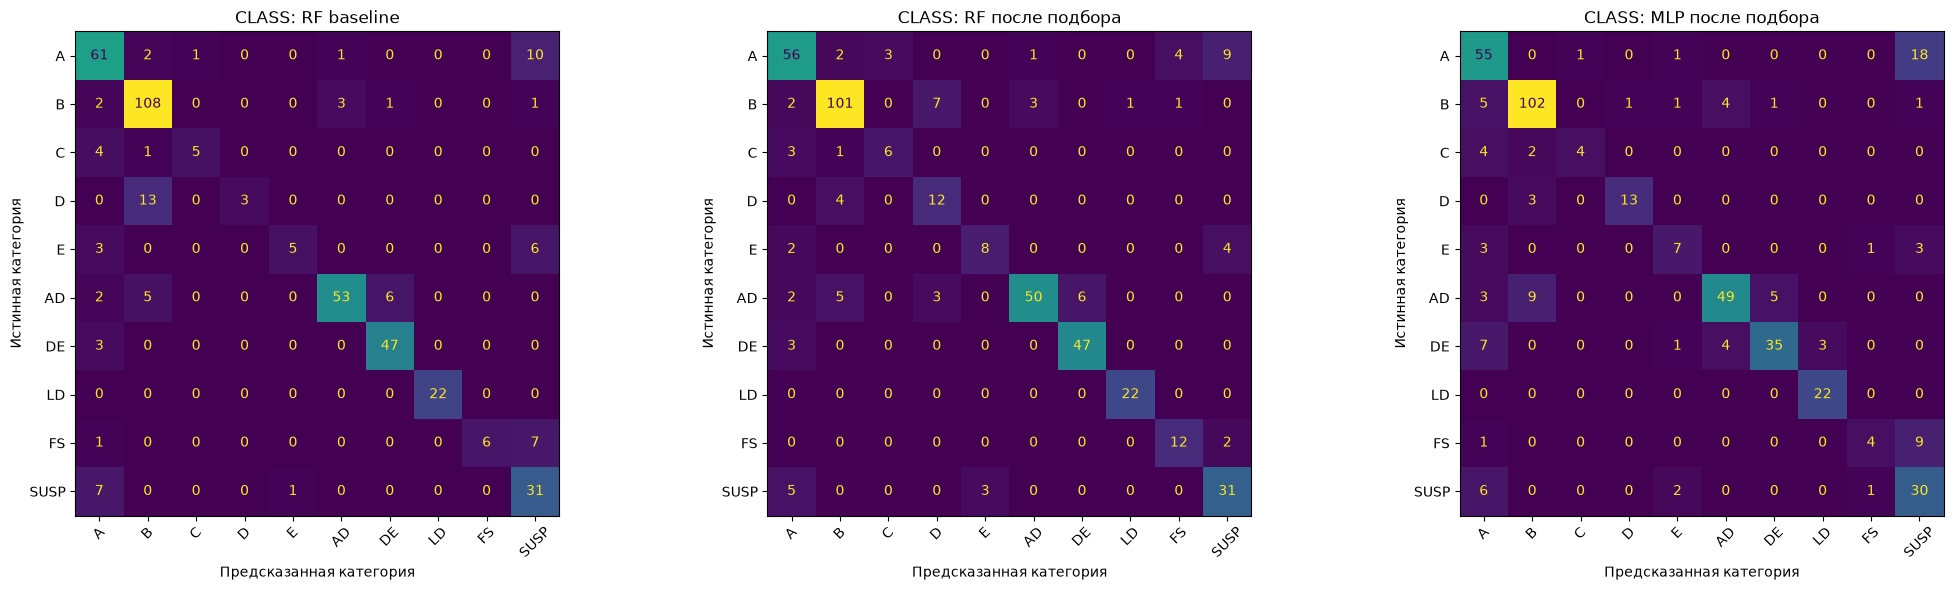

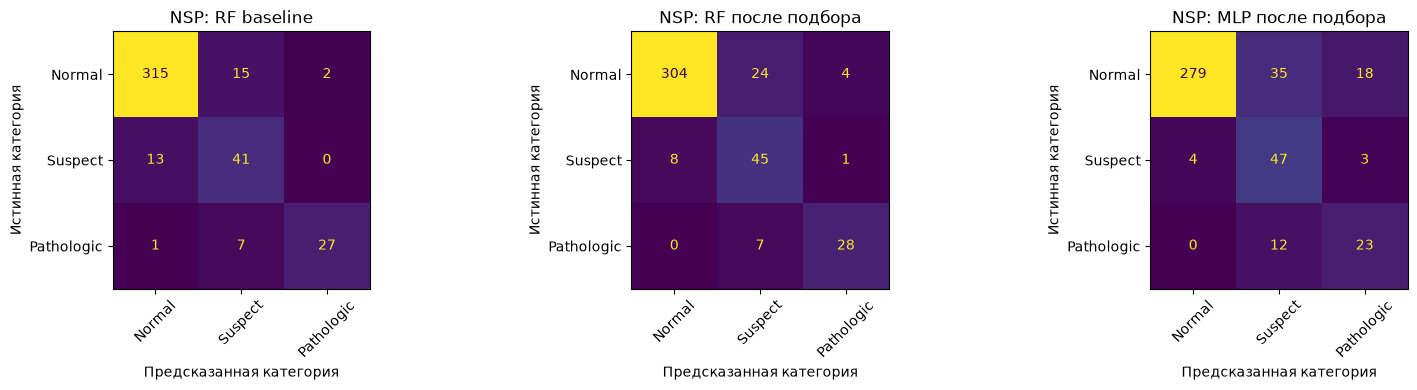

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

for target, mapping in target_mappings.items():
    fig, axes = plt.subplots(1, 3, figsize=(21, 6) if target == dataset_schema.ClassificationTarget.CLASS else (16, 4))
    for ax, name in zip(axes, ["RF baseline", "RF после подбора", "MLP после подбора"]):
        ConfusionMatrixDisplay(
            confusion_matrix=final_test_results[(target, name)]["confusion"],
            display_labels=list(mapping.values()),
        ).plot(ax=ax, colorbar=False, xticks_rotation=45)
        ax.set_title(f"{target.value}: {name}")
        ax.set_xlabel("Предсказанная категория")
        ax.set_ylabel("Истинная категория")
    fig.tight_layout()
    plt.show()

### Ошибки NSP, важные для приоритизации

Отдельно сравниваем записи без предупреждения — Pathologic → Normal и Suspect → Normal, занижение Pathologic до Suspect и ложные предупреждения для Normal. Ложное предупреждение менее вредно для выбранного сценария, но увеличивает объём проверки.

In [16]:
nsp_test_errors = []
for name in ["RF baseline", "RF после подбора", "MLP после подбора"]:
    matrix = final_test_results[(dataset_schema.ClassificationTarget.NSP, name)]["confusion"]
    nsp_test_errors.append(
        {
            "Модель": name,
            "Pathologic → Normal": int(matrix[2, 0]),
            "Suspect → Normal": int(matrix[1, 0]),
            "Pathologic → Suspect": int(matrix[2, 1]),
            "Normal → Suspect/Pathologic": int(matrix[0, 1] + matrix[0, 2]),
        },
    )
pd.DataFrame(nsp_test_errors).set_index("Модель")

,Pathologic → Normal,Suspect → Normal,Pathologic → Suspect,Normal → Suspect/Pathologic
Модель,,,,
RF baseline,1,13,7,17
RF после подбора,0,8,7,28
MLP после подбора,0,4,12,53


## 8. Итоговые выводы

Оценены шесть сохранённых моделей: три варианта для каждой цели. Все результаты ниже получены на одних и тех же 421 записях test. Повторного обучения и подбора параметров на этом этапе не было.

| Модель | CLASS: macro-F1 | NSP: macro-F1 |
|---|---:|---:|
| RF baseline | 0,712 | 0,833 |
| RF после подбора | 0,777 | 0,820 |
| MLP после подбора | 0,702 | 0,708 |

**1. CLASS — выбираем оптимизированный RandomForest.**

- У леса после подбора macro-F1 0,777, weighted-F1 0,821 и accuracy 0,819. Это лучше baseline: 0,712, 0,799 и 0,810 соответственно.
- MLP получила macro-F1 0,702, weighted-F1 0,762 и accuracy 0,762. Она уступает обеим версиям леса по этим показателям.
- Один из заметных источников ошибок MLP — FS: правильно определены 4 из 14 записей, у оптимизированного леса — 12 из 14. Кроме того, 18 записей A отнесены к SUSP.

**2. NSP — результат зависит от того, какие ошибки считаем важными.**

| Ошибка | RF baseline | RF после подбора | MLP после подбора |
|---|---:|---:|---:|
| Pathologic → Normal | 1 | 0 | 0 |
| Suspect → Normal | 13 | 8 | 4 |
| Pathologic → Suspect | 7 | 7 | 12 |
| Normal → Suspect/Pathologic | 17 | 28 | 53 |

- По общим метрикам MLP слабее: macro-F1 0,708, weighted-F1 0,845, accuracy 0,829. У оптимизированного леса — 0,820, 0,902 и 0,895.
- MLP оставляет без предупреждения меньше Suspect: 4 вместо 8. Ни одна Pathologic не отнесена к Normal у обеих оптимизированных моделей.
- При этом MLP чаще занижает Pathologic до Suspect: 12 вместо 7. Точно определены 23 из 35 Pathologic, у леса — 28 из 35.
- Ложных предупреждений у MLP на 25 больше: 53 вместо 28. Ложное предупреждение менее вредно, чем отсутствие предупреждения, но это не делает любой рост их числа приемлемым независимо от других ошибок.

**3. Какие модели используем для демо.**

Для обеих целей фиксируем **оптимизированный RandomForest как основной вариант**. Для CLASS он даёт лучший общий результат. Для NSP он сохраняет отсутствие Pathologic → Normal, уменьшает пропуски Suspect относительно baseline и точнее определяет патологическую категорию, чем MLP.

MLP сохраняем как отдельный вариант для выбора через API и демонстрации. Для NSP она может быть полезна, если приоритетом становится минимизация записей без предупреждения: таких записей 4, у оптимизированного леса — 8. Это компромисс с большим числом ложных предупреждений и заниженных патологических категорий; улучшением по всем критериям его не считаем.

**4. Почему результат MLP на validation не подтвердился на test.**

Для CLASS macro-F1 изменился с 0,843 на validation до 0,702 на test; для NSP — с 0,865 до 0,708. Найденные настройки хорошо подошли validation, но не обеспечили такой же результат на других исследованиях. Возможна подстройка к validation при выборе среди 25 попыток и множества эпох; по одному разбиению нельзя установить единственную причину.

Для NSP в матрице видно конкретное ухудшение: ложные предупреждения выросли с 27 на validation до 53 на test, при близком числе Normal — 328 и 332. Recall Pathologic снизился с 0,824 до 0,657. Эти ошибки объясняют ухудшение precision и F1. Сравнение CLASS и NSP показывает, что большая глубина или использование нейросети сами по себе не гарантируют преимущества над классической моделью.

**5. Ограничения и завершение исследования.**

Параметры и нейросетевые кандидаты зафиксированы по validation. Test уже просматривался в классических экспериментах и учтён при окончательном выборе основного варианта; это не полностью новая независимая проверка. По этим результатам дальнейший подбор параметров не проводим.

Эксперименты и test-отчёты сохранены в MLflow. Улучшение CLASS относительно baseline подтвердилось у RandomForest; для NSP обоснован компромисс по ошибкам приоритизации. Нейросеть не превзошла лес по общим метрикам, но её обучение, подбор и ограничения исследованы. Далее сохраняем комплект MLP для загрузки сервисом без обучения.

## 9. Сохранение нейросетевых артефактов

Выбранные MLP уже зарегистрированы в MLflow. Дополнительно сохраняем локальный комплект в runtime/models/neural/ для загрузки сервисом без обучения:

- class.pt и nsp.pt — только веса сетей;
- class.json и nsp.json — архитектура и параметры, порядок признаков, метки, выбранная эпоха, идентификатор MLflow и метрики;
- scaler.joblib — преобразование признаков, обученное по train;
- requirements.txt — зависимости из lock-файла.

Сохраняем обе MLP, чтобы сервис мог демонстрировать нейросетевой вариант для каждой цели, независимо от выбранной модели по умолчанию.

In [17]:
models_dir = dataset_schema.PROJECT_ROOT / "runtime" / "models" / "neural"
models_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(scaler, models_dir / "scaler.joblib")
for target, result in selected_neural_results.items():
    model_path = models_dir / f"{target.value.lower()}.pt"
    torch.save(result["model"].state_dict(), model_path)
    metadata = {
        "target": target.value,
        "features": feature_cols,
        "target_mapping": target_mappings[target],
        "parameters": result["parameters"].model_dump(),
        "random_state": experiment_settings.random_state,
        "batch_size": experiment_settings.neural_batch_size,
        "best_epoch": result["best_epoch"],
        "epochs_completed": len(result["history"]),
        "mlflow_run_id": result["run_id"],
        "validation_metrics": {key: value for key, value in result["metrics"].items() if key.startswith("validation_")},
        "test_metrics": final_test_results[(target, "MLP после подбора")]["metrics"],
    }
    model_path.with_suffix(".json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
print(f"Нейросетевые артефакты сохранены: {models_dir}")

Нейросетевые артефакты сохранены: /Users/mikhail_afanasiev/Dev/netology/netology-aiepro-diplom/runtime/models/neural
